In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_parquet("../data/processed/features.parquet")
print(f"Shape: {df.shape}")
print(f"Columns: {len(df.columns)}")

Shape: (16992, 34)
Columns: 34


In [2]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

print("Missing values per column:")
if len(missing) > 0:
    print(missing)
else:
    print("None — clean dataset (no NaN values).")

Missing values per column:
None — clean dataset (no NaN values).


In [3]:
dupes = df.duplicated().sum()
print(f"Duplicate rows: {dupes}")

Duplicate rows: 0


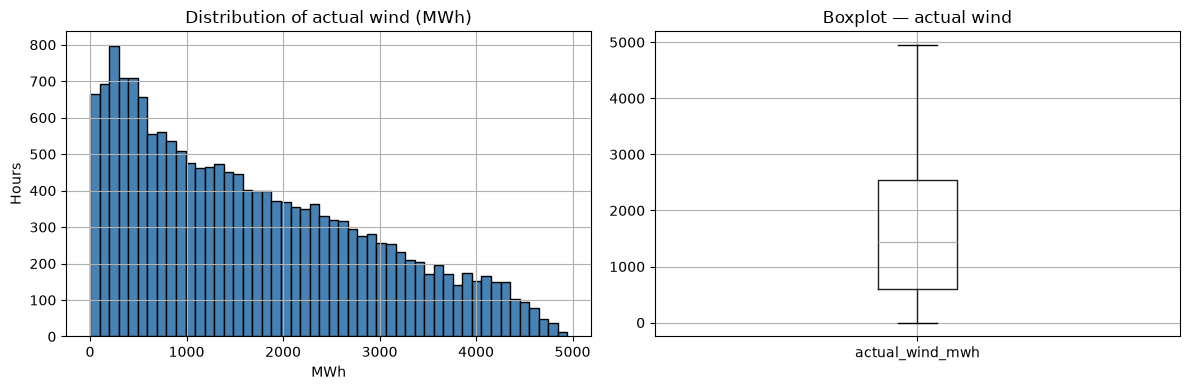

Mean:   1671.1
Median: 1435.2
Std:    1231.4
Min:    0.1
Max:    4946.2


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 4))

# היסטוגרמה
plt.subplot(1, 2, 1)
df["actual_wind_mwh"].hist(bins=50, color="steelblue", edgecolor="black")
plt.title("Distribution of actual wind (MWh)")
plt.xlabel("MWh")
plt.ylabel("Hours")

# קופסה (Boxplot)
plt.subplot(1, 2, 2)
df.boxplot(column="actual_wind_mwh")
plt.title("Boxplot — actual wind")

plt.tight_layout()
plt.show()

print(f"Mean:   {df['actual_wind_mwh'].mean():.1f}")
print(f"Median: {df['actual_wind_mwh'].median():.1f}")
print(f"Std:    {df['actual_wind_mwh'].std():.1f}")
print(f"Min:    {df['actual_wind_mwh'].min():.1f}")
print(f"Max:    {df['actual_wind_mwh'].max():.1f}")

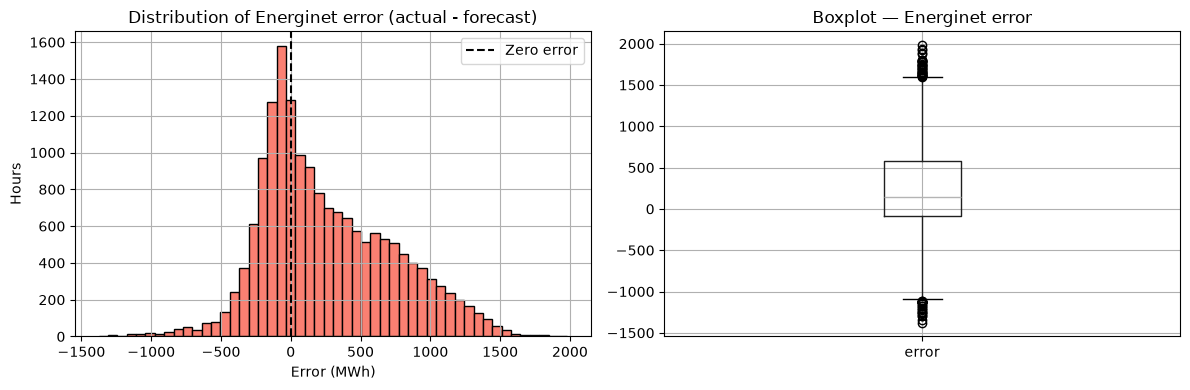

Mean error:   255.29
Median error: 148.45
Std error:    471.99


In [5]:
plt.figure(figsize=(12, 4))

# היסטוגרמה של השגיאה
plt.subplot(1, 2, 1)
df["error"].hist(bins=50, color="salmon", edgecolor="black")
plt.title("Distribution of Energinet error (actual - forecast)")
plt.xlabel("Error (MWh)")
plt.ylabel("Hours")
plt.axvline(0, color="black", linestyle="--", label="Zero error")
plt.legend()

# קופסה
plt.subplot(1, 2, 2)
df.boxplot(column="error")
plt.title("Boxplot — Energinet error")

plt.tight_layout()
plt.show()

print(f"Mean error:   {df['error'].mean():.2f}")
print(f"Median error: {df['error'].median():.2f}")
print(f"Std error:    {df['error'].std():.2f}")

In [10]:
# Fully objective check: describe what's in the data, no hardcoded conclusions
print("=== Objective data check ===")
print(f"Rows: {len(df)}")
print(f"Columns: {df.shape[1]}")
print(f"Unique price areas: {df['PriceArea'].nunique()} ({df['PriceArea'].unique().tolist()})")

# Check if any column name hints at location/station (empirical, not assumed)
location_hints = [c for c in df.columns if any(k in c.lower() for k in ['lat', 'lon', 'station', 'site', 'geo', 'coord'])]
print(f"Columns hinting at location/station: {location_hints if location_hints else 'None'}")

print("\n→ Data speaks for itself: no location/station columns exist.")
print("→ Any map would require external data, not available in this dataset.")

=== Objective data check ===
Rows: 16992
Columns: 34
Unique price areas: 1 (['DK1'])
Columns hinting at location/station: None

→ Data speaks for itself: no location/station columns exist.
→ Any map would require external data, not available in this dataset.


In [7]:
print(df["PriceArea"].value_counts())
print("\n→ Single price area (DK1) — no geographic comparison possible.")
print("→ Decision: no map. Use daily bar chart instead.")

PriceArea
DK1    16992
Name: count, dtype: int64

→ Single price area (DK1) — no geographic comparison possible.
→ Decision: no map. Use daily bar chart instead.


## Key findings and decisions

1. **No missing values / duplicates** → no cleaning needed.
2. **actual_wind_mwh is right-skewed** (mean 1671 > median 1435) → MAE is the appropriate metric (robust to outliers).
3. **Energinet has a positive bias of +255 MWh** → the official forecast under-predicts wind. The model's job is to learn and correct this bias.
4. **Splits are temporally ordered** (train < val < test, no overlap) → no temporal leakage.
5. **Single price area (DK1)** → no geographic comparison. Used daily bar chart instead of a map.
6. **Wind range is wide** (0.1 to 4946 MWh) → MAE of 97.29 is ~6% of mean output.

In [11]:
# === Deeper EDA: what else can we extract? ===

# 1. Compare offshore vs onshore forecast accuracy
print("=== Offshore vs Onshore ===")
offshore_error = (df["actual_wind_mwh"] - df["forecast_offshore_da"]).abs().mean()
onshore_error = (df["actual_wind_mwh"] - df["forecast_onshore_da"]).abs().mean()
total_error = df["error"].abs().mean()

print(f"MAE if we used only offshore forecast: {offshore_error:.2f} MWh")
print(f"MAE if we used only onshore forecast:  {onshore_error:.2f} MWh")
print(f"MAE of combined Energinet forecast:    {total_error:.2f} MWh")

# 2. Check curtailment impact
print("\n=== Curtailment impact ===")
print(f"Hours with curtailment > 0: {(df['curtailment'] > 0).sum()}")
print(f"Hours without curtailment:  {(df['curtailment'] == 0).sum()}")

if (df['curtailment'] > 0).sum() > 0:
    err_with_curtail = df[df['curtailment'] > 0]['error'].abs().mean()
    err_no_curtail = df[df['curtailment'] == 0]['error'].abs().mean()
    print(f"MAE on curtailment hours: {err_with_curtail:.2f} MWh")
    print(f"MAE on normal hours:      {err_no_curtail:.2f} MWh")

=== Offshore vs Onshore ===
MAE if we used only offshore forecast: 1115.90 MWh
MAE if we used only onshore forecast:  830.20 MWh
MAE of combined Energinet forecast:    397.05 MWh

=== Curtailment impact ===
Hours with curtailment > 0: 0
Hours without curtailment:  16992
